In this meeting we will see that a lot of important ODEs in physics actually arrive from us trying to solve PDEs. To begin we make the assumption that we know the equation $\Delta u = 0$ is important in physics. This is known as the Laplace equation. We will see later that this is in fact very important. 

Note that the above could be in a variety of geometries. In regular old cartesian coordinates with the usual metric, this is written as $\Delta u = \sum_{i}\partial_i^2 u$. For example, in $2$ dimensions, this is $\Delta u = u_{xx} + u_{yy}$. This is the situation we will focus on for now. For later convienience we will note that in polar coordinates 
\begin{align*}
    x &= r\cos\theta \\
    y &= r\sin\theta
\end{align*}
the laplacian is given by $\Delta u = u_{rr} + \frac{1}{r}u_r + \frac{1}{r^2}u_{\theta\theta}$

Let us start with the cartesian case. Suppose that we have a function $u$ such that $\Delta u = 0$. Now we assume that $u = X(x)Y(y)$ for some smooth enough functions $X, Y$. The important thing to note is that we are assuming that $u$ is $\textit{seperable}$. Not all functions are, so why can we make this assumption? As it turns out, we can approximate any solution of the equation above by adding together seperable solutions (with additional constraints but since we are simulating on a computer we need not really worry about those). 

Substituing the seperable condition we get that $X''Y + XY'' = 0$. Note that we may assume that $u \neq 0$ since that is already a solution. In particular we note that $X, Y$ are not always $0$. Hence we divide by $u$ to get $\frac{X''}{X} + \frac{Y''}{Y} = 0$. Now $\frac{X''}{X}$ is a function of only $x$ and $\frac{Y''}{Y}$ is a function of only $y$. But their sum is constant hence each of them must be constant individually. This gives $X'' = \lambda X$ and $Y'' = -\lambda Y$.

Now since the arbitrary domain is not compact the value of $k$ is free to be whatever it wants to be. But say we were simulating this equation on a (flat) torus. In this case we would require that the functions and its derivatives be $2\pi$ periodic since the torus is simply the rectangle with the opposite sides identified. Usually this is drawn as follows:

<img src="torus_diagram.png">

So in this case we have $X(0) = X(2\pi)$, $X'(0) = X'(2\pi)$, $Y(0) = Y(2\pi)$ and finally $Y'(0) = Y'(2\pi)$. Note that we need two conditions for each since these are second order differential equations. 

So we basically have $3$ cases that is $\lambda = 0$, $\lambda > 0$ and $\lambda < 0$. If $\lambda = 0$ then we get $X(x) = ax + b$ but since $X(0) = X(2\pi)$ we get that $a = 0$. Similarly since $Y(y) = cy + d$ we get that $c = 0$. Hence the only solutions we get are constant.

Exercise: Show that this is the only solution.

The point of the above is that the ODEs we get are not too interesting in $2$ variables in cartesian coordinates. So we look at polar coordinates in hope for more interesting ODEs.

As mentioned above, in polar coordinates we have $\Delta u = u_{rr} + \frac{1}{r}u_r + \frac{1}{r^2}u_{\theta\theta}$. Now make the same assumption that $u = R(r)\Theta(\theta)$ then note that we get $R''\Theta + \frac{1}{r}R'\Theta + \frac{1}{r^2}R\Theta'' = 0$. Assumign $R, \Theta \neq 0$ we get that $r^2\frac{R''}{R} + r\frac{R'}{R} + \frac{\Theta'}{\Theta} = 0$. We now make the assumption that we are working in the full disk, this gives a boundary condition that $\Theta(0) = \Theta(2\pi)$.

Similar to the cartesian case we have $r^2R'' + rR' - lR = 0$ and $\Theta'' + l\Theta = 0$. It is much simpler to solve the $\Theta$ equation for allowed values of $l$. One can check that $l > 0$ moreover $l = n^2$ where $n \in \mathbb{N}$. So we get a family of solutions $\Theta_n(\theta) = A_n\cos(n\theta) + B_n\sin(n\theta)$. We can now use these to simulate for the solutions of the $R$ equation in some finite interval, which is what we will do now.

Let us start, in this case we have that $r^2R'' + rR' = n^2R$. So to solve this, we need to turn this into a system of first order differential equations. Let $Q = R'$ and so we get the following system 
\begin{align*}
    R' &= Q \\
    Q' &= -\frac{1}{r}Q + \frac{n^2}{r^2}R
\end{align*}
For simplicity we will simulate this on $(0, 1]$. 

We will make use of the scipy function called `odeint`. This takes in a function we want to simulate, the initial conditions we want and the time interval over which we need to solve the equation.

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

Next we define the function which specifies our ODE. Note that we need input a vector into the function since it a function of two variables and we will make use of the fact that python can seperate the entries of a vector as you please.

In [66]:
def f(x, r, n):
    R, Q = x
    return [Q, (-1/r)*Q + ((n**2)/(r**2))*R]

def g(x, n):
    return 1/(x**(n))

In this case our $r$ is acting like $t$.

In [73]:
#Specifying the range over which we want to solve the ODE
t_i = 1
t_f = 2
times = np.linspace(t_i,t_f,1000)

#Specifying initial conditions
R_i = 1
Q_i = -2

#Specifying parameters
n = 2

Now we actually the ODE using the `odeint` function.

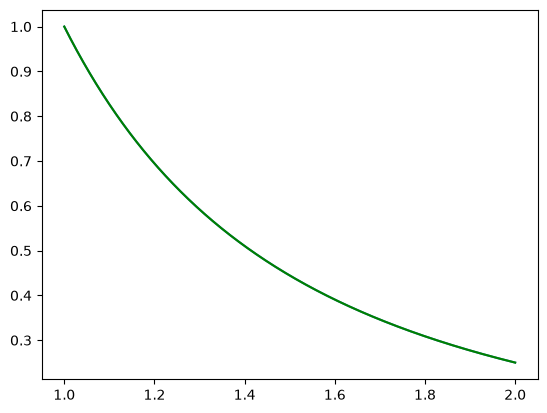

In [ ]:
            #function defining ODE, inital conditions, times we want to solve for, addition arguments that the ODE function takes in
sol = odeint(f, [R_i, Q_i], times, args = (n,))
plt.plot(times, sol.T[0])
plt.plot(times, g(times, n), 'g')
plt.show()

But we can also make an educated guess as to what the solution is. Let u sguess that the solution is of the form $R(r) = r^\alpha$ then we see that $R' = \alpha r^{\alpha-1}$ and $R'' = \alpha(\alpha - 1)r^{\alpha - 2}$. Putting this all into the equation above we get that $\alpha(\alpha - 1) + \alpha = n^2$ hence $\alpha^2 = n^2$ so we get $\alpha = \pm n$. So the radial solutions are given by $R_n(r) = C_nr^{n} + D_nr^{-n}$. This works as long as $n \neq 0$. In that case we have $r^2R'' + rR' = 0$ integrating once we get that $R' = \frac{D}{r}$ where we absorb the negative sign into the integration and so integrating again we get $R_0(r) = C + D\ln r$.

How do we combine all these solutions together? Well our initial idea was to put all the solutions together by adding them. So we would have that 
\begin{equation*}
    u(r, \theta) = C + D\ln r + \sum_{n = 1}^{\infty}\left(C_nr^{n} + D_nr^{-n}\right)(A_n\cos(n\theta) + B_n\sin(n\theta))
\end{equation*}

And now actually determining these coefficients is a story for another day. We will talk more about these when we talk about how to solve PDEs. For now what is important is that we get different ODEs in physics through considering PDEs that arise more natually.

Let us do another sample calculation for the dynamics of a damped spring. In this case our ODE is given by $m\ddot{y} + \gamma\dot{y} + ky = 0$ where $k \geq 0$. We can then introduce the variable $v = \dot{y}$ and get a system of ODEs as 
\begin{align*}
    \dot{y} &= v \\
    \dot{v} &= -\gamma v -\frac{k}{m}y
\end{align*}

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

#Defining function of the ODE
def F(x, t, m, gamma, k):
    y, v = x
    return [v, -gamma*v -(k/m)*y]

def Energy(x, m, k):
    y, v = x
    return (1/2)*m*(v**2) + (1/2)*k*(y**2)

#Intializing times
t_i = 0
t_f = 10
times = np.linspace(t_i,t_f,1000)

#Intial Conditions
y_i = 1
ydot_i = -1
m = 1
gamma = 1
k = 1

sol = odeint(F, [y_i, ydot_i], times, args=(m, gamma, k))
pos = sol.T[0]
vel = sol.T[1]

#This makes a plot with 1 row of graphs and 2 coloumns that share a y axis
fig, plot = plt.subplots(2, 2)
plt.subplots_adjust(bottom=0, right=2, top=1.5)

plot[0, 0].set_title('Position')
plot[0, 0].set_ylabel('Distance from equilibrium')
plot[0, 0].plot(times, pos, 'b')

plot[0, 1].set_title('Velocity')
plot[0, 1].plot(times, vel, 'r')

plot[1, 0].set_title('Energy')
plot[1, 0].plot(times, Energy([pos, vel], m, k), 'g')

plot[1, 1].set_title('Energy Difference')
plot[1, 1].plot(times, 1 - Energy([pos, vel], m, k), 'g')

plt.show()

: 

Now in quantum mechanics the equation of motion is determined by $i\hbar\partial_t\psi = \mathcal{H}\psi$ where $\mathcal{H}$ is the Hamiltonian of the system. We usually take the Hamiltonian to be $\mathcal{H} = -\frac{\hbar^2}{2m}\Delta + V$ for some potential function $V$. Again the PDE is not important, what we can do is seperate out the time depedence out and we get the time independent Schrodinger equation $\mathcal{H}\psi = E\psi$ for some constant $E$.

If we have $V = mgx$ (which is for a particle under the influence of gravity) we get the following ODE in the one dimensional case 
\begin{align*}
    -\psi'' + x\psi = E\psi
\end{align*}
assuming $\hbar = 1 = m = g$ we can do a shift in the $x$ coordinate to also get rid of the $E$ term so we get 
\begin{align*}
    \psi'' - x\psi = 0
\end{align*}
This is called the Airy equation. It has two linearly independent solutions called the Airy functions. We simulate them below:

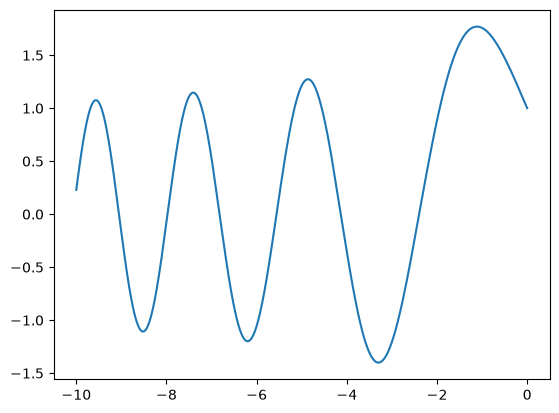

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from scipy import special

#Defining function of the ODE
def f(x, t):
    y, ydot = x
    return [ydot, t*y]

#Intializing times
t_i = 0
t_f = -10
times = np.linspace(t_i,t_f,1000)

#Intial Conditions
y_i = 1
ydot_i = -1

sol = odeint(f,[y_i,ydot_i],times)

plt.plot(times, sol.T[0])
plt.show()